# A2 — Hydraulic Test Rig — Exploratory Data Analysis
## ZeMA Condition Monitoring Dataset

**Document**: JESA-DT-EDA-A2-002  |  **Revision**: 1.1  |  **Date**: 2026-07-13
**Phase**: 2 — Identification des attributs
**Reference**: `docs/asset-attribute-map.md` §5

### Objectives
1. Validate multi-rate dataset structure (17 sensors at 1 / 10 / 100 Hz).
2. Confirm declared statistical ranges (§5.1) from raw data.
3. Visualise sensor distributions grouped by component condition (like A1 §3).
4. Visualise multi-rate signals within a single 60-second cycle.
5. Analyse condition label distribution and co-occurrence across 2,205 cycles.
6. Identify degradation signatures — sensor response to component deterioration.
7. Justify the 1 Hz downsampling decision for UNS publishing.
8. Validate simulator replay decisions.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec

REPO     = pathlib.Path.cwd().parent
A2_DIR   = REPO / "condition+monitoring+of+hydraulic+systems"
PREP     = REPO / "sim" / "data" / "a2_1hz.npz"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "sans-serif",
                     "axes.titlesize": 10, "axes.labelsize": 9})

SENSORS = {
    "PS1":("bar",100),"PS2":("bar",100),"PS3":("bar",100),
    "PS4":("bar",100),"PS5":("bar",100),"PS6":("bar",100),
    "EPS1":("W",100),
    "FS1":("l/min",10),"FS2":("l/min",10),
    "TS1":("degC",1),"TS2":("degC",1),"TS3":("degC",1),"TS4":("degC",1),
    "VS1":("mm/s",1),"CE":("%",1),"CP":("kW",1),"SE":("%",1),
}

# Condition colour palettes
COOLER_PAL  = {3: "#E84C4C", 20: "#F5A623", 100: "#10B981"}
VALVE_PAL   = {73: "#E84C4C", 80: "#F5A623", 90: "#4C9BE8", 100: "#10B981"}
PUMP_PAL    = {0: "#10B981", 1: "#F5A623", 2: "#E84C4C"}
ACCUM_PAL   = {90: "#E84C4C", 100: "#F5A623", 115: "#4C9BE8", 130: "#10B981"}

print(f"A2 dataset dir : {A2_DIR}  exists={A2_DIR.exists()}")
print(f"Preprocessed   : {PREP}  exists={PREP.exists()}")

A2 dataset dir : c:\Users\MSI\Documents\jesa\condition+monitoring+of+hydraulic+systems  exists=True
Preprocessed   : c:\Users\MSI\Documents\jesa\sim\data\a2_1hz.npz  exists=True


## 1. Dataset structure validation

In [2]:
data = {}
for s, (unit, hz) in SENSORS.items():
    arr = np.loadtxt(A2_DIR / f"{s}.txt")
    data[s] = arr
    print(f"  {s:<6s} ({unit:6s} @{hz:3d}Hz): shape={arr.shape}  "
          f"min={arr.min():.2f}  max={arr.max():.2f}")

profile = np.loadtxt(A2_DIR / "profile.txt")
print(f"\n  profile: shape={profile.shape}  "
      f"columns=[Cooler%, Valve%, PumpLeak, Accum_bar, StableFlag]")

for s, (unit, hz) in SENSORS.items():
    assert data[s].shape == (2205, hz * 60), f"Shape mismatch for {s}"
assert profile.shape == (2205, 5)
print("\n✓ All 17 sensor shapes validated  ✓ profile.txt shape (2205, 5) validated")

# Cycle means (feature matrix)
means = {s: data[s].mean(axis=1) for s in SENSORS}
cooler = profile[:, 0].astype(int)
valve  = profile[:, 1].astype(int)
pump   = profile[:, 2].astype(int)
accum  = profile[:, 3].astype(int)
stable = profile[:, 4].astype(bool)

  PS1    (bar    @100Hz): shape=(2205, 6000)  min=133.13  max=191.92
  PS2    (bar    @100Hz): shape=(2205, 6000)  min=0.00  max=167.77
  PS3    (bar    @100Hz): shape=(2205, 6000)  min=0.00  max=18.83
  PS4    (bar    @100Hz): shape=(2205, 6000)  min=0.00  max=10.27
  PS5    (bar    @100Hz): shape=(2205, 6000)  min=8.32  max=10.04
  PS6    (bar    @100Hz): shape=(2205, 6000)  min=8.27  max=9.91
  EPS1   (W      @100Hz): shape=(2205, 6000)  min=2097.80  max=2995.20
  FS1    (l/min  @ 10Hz): shape=(2205, 600)  min=0.00  max=20.48
  FS2    (l/min  @ 10Hz): shape=(2205, 600)  min=8.76  max=10.45
  TS1    (degC   @  1Hz): shape=(2205, 60)  min=34.98  max=58.21
  TS2    (degC   @  1Hz): shape=(2205, 60)  min=40.71  max=62.18
  TS3    (degC   @  1Hz): shape=(2205, 60)  min=38.15  max=59.54
  TS4    (degC   @  1Hz): shape=(2205, 60)  min=30.36  max=53.15
  VS1    (mm/s   @  1Hz): shape=(2205, 60)  min=0.48  max=2.55
  CE     (%      @  1Hz): shape=(2205, 60)  min=17.04  max=48.78
  CP     (kW

## 2. Descriptive statistics — cross-checked against attribute-map.md §5.1

In [3]:
EXPECTED = {
    "PS1": (133.1,191.9), "PS2": (0.0,167.8),   "PS3": (0.0,18.8),
    "PS4": (0.0,10.3),    "PS5": (8.3,10.0),    "PS6": (8.3,9.9),
    "EPS1":(2097.8,2995.2),"FS1":(0.0,20.5),    "FS2": (8.8,10.5),
    "TS1": (35.0,58.2),   "TS2": (40.7,62.2),   "TS3": (38.2,59.5),
    "TS4": (30.4,53.2),   "VS1": (0.5,2.6),     "CE":  (17.0,48.8),
    "CP":  (1.0,2.9),     "SE":  (0.0,100.6),
}
all_ok = True
print(f"{'Sensor':<6s}  {'Unit':6s}  {'Hz':>4s}  {'Min':>8s}  {'Max':>8s}  {'Mean':>8s}  {'Std':>8s}  Check")
print("-" * 72)
for s, (unit, hz) in SENSORS.items():
    arr = data[s].flatten()
    lo, hi, mu, sd = arr.min(), arr.max(), arr.mean(), arr.std()
    elo, ehi = EXPECTED[s]
    ok  = abs(lo - elo) < 0.5 and abs(hi - ehi) < 0.5
    sym = "OK" if ok else "FAIL"
    if not ok: all_ok = False
    print(f"{s:<6s}  {unit:6s}  {hz:>4d}  {lo:>8.2f}  {hi:>8.2f}  {mu:>8.2f}  {sd:>8.2f}  [{sym}]")
print()
print("✓ All ranges match attribute-map.md §5.1" if all_ok else "RANGE MISMATCH")

Sensor  Unit      Hz       Min       Max      Mean       Std  Check
------------------------------------------------------------------------
PS1     bar      100    133.13    191.92    160.49     16.13  [OK]
PS2     bar      100      0.00    167.77    109.38     48.10  [OK]
PS3     bar      100      0.00     18.83      1.75      0.93  [OK]
PS4     bar      100      0.00     10.27      2.60      4.30  [OK]
PS5     bar      100      8.32     10.04      9.16      0.58  [OK]
PS6     bar      100      8.27      9.91      9.08      0.55  [OK]
EPS1    W        100   2097.80   2995.20   2495.51    218.22  [OK]
FS1     l/min     10      0.00     20.48      6.20      3.21  [OK]
FS2     l/min     10      8.76     10.45      9.65      0.45  [OK]
TS1     degC       1     34.98     58.21     45.42      7.99  [OK]
TS2     degC       1     40.71     62.18     50.37      7.40  [OK]
TS3     degC       1     38.15     59.54     47.66      7.45  [OK]
TS4     degC       1     30.36     53.15     40.74     

## 3. Sensor distributions — cycle means grouped by component condition

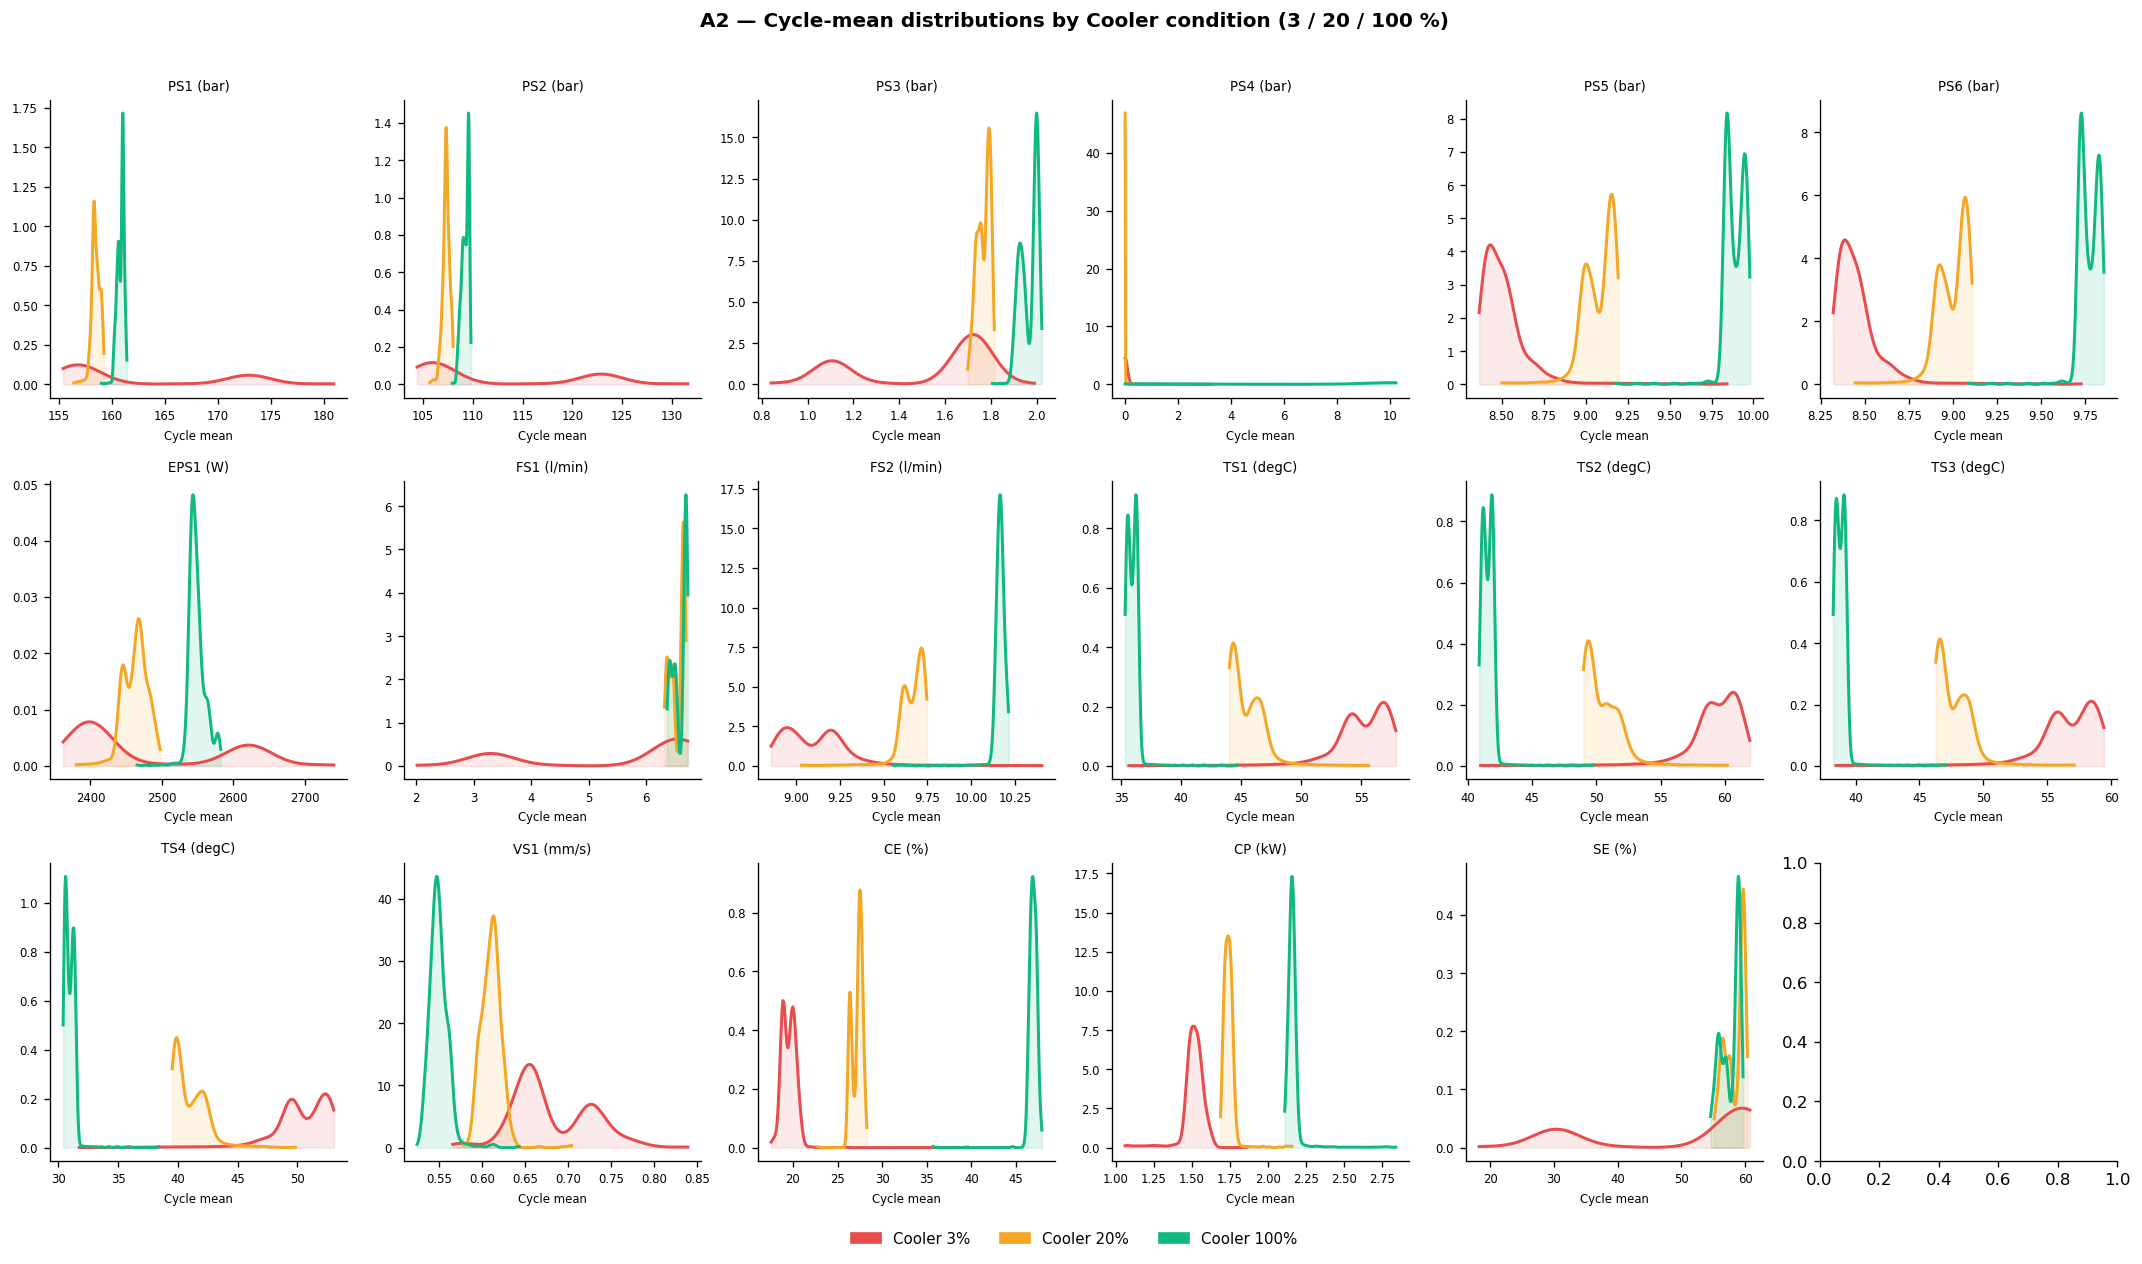

Saved: A2_sensor_distributions.png


In [4]:
# ── Row 0: all 17 cycle-mean distributions (KDE), coloured by cooler condition
#    mirrors A1 §3 style: one panel per sensor, distribution by condition level
fig, axes = plt.subplots(3, 6, figsize=(18, 10))
fig.suptitle("A2 — Cycle-mean distributions by Cooler condition (3 / 20 / 100 %)",
             fontsize=12, fontweight="bold", y=1.01)
axes = axes.flat

sensor_list = list(SENSORS.keys())
for ax, s in zip(axes, sensor_list):
    unit = SENSORS[s][0]
    for cval, ccolor in COOLER_PAL.items():
        mask = cooler == cval
        vals = means[s][mask]
        if len(vals) > 1:
            from scipy.stats import gaussian_kde
            xs = np.linspace(vals.min(), vals.max(), 200)
            try:
                kde = gaussian_kde(vals)
                ax.plot(xs, kde(xs), color=ccolor, lw=1.8, label=f"C={cval}%")
                ax.fill_between(xs, kde(xs), alpha=0.12, color=ccolor)
            except Exception:
                ax.hist(vals, bins=20, color=ccolor, alpha=0.4, density=True)
    ax.set_title(f"{s} ({unit})", fontsize=8)
    ax.set_xlabel("Cycle mean", fontsize=7)
    ax.tick_params(labelsize=7)

# Hide the last empty panel if any
for ax in list(axes)[len(sensor_list):]:
    ax.set_visible(False)

patches = [mpatches.Patch(color=c, label=f"Cooler {v}%") for v, c in COOLER_PAL.items()]
fig.legend(handles=patches, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("A2_sensor_distributions.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_sensor_distributions.png")

## 4. Multi-rate signal visualisation — single 60-second cycle

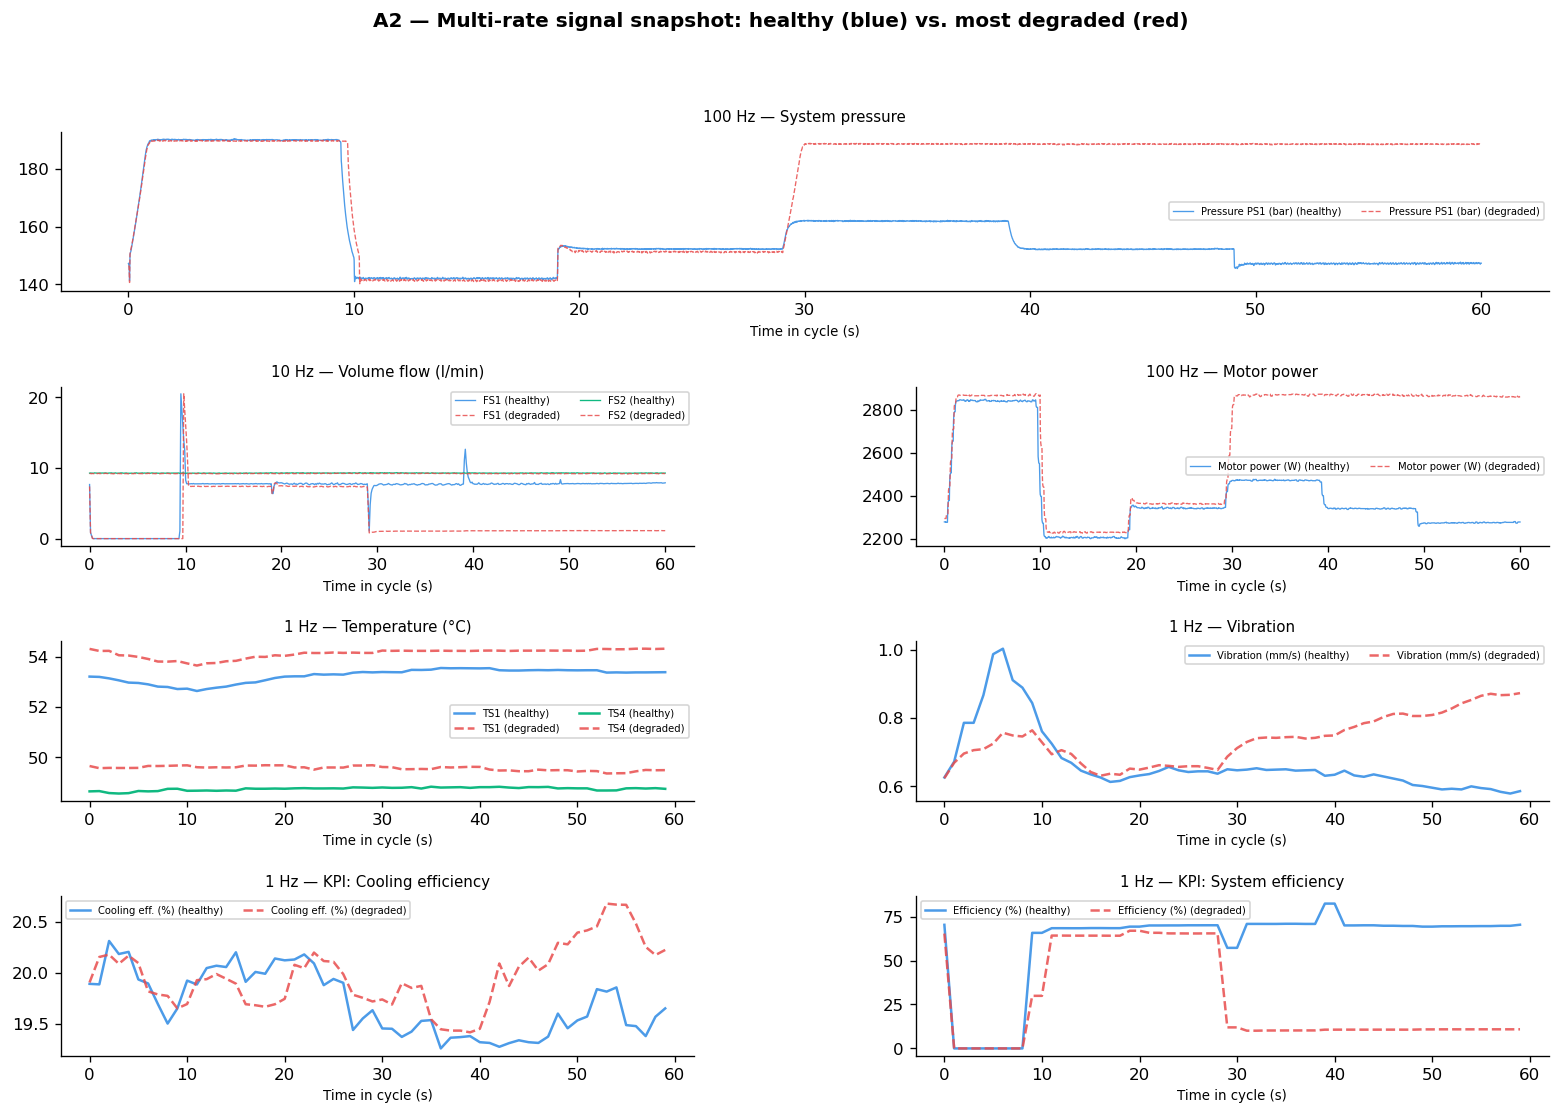

Cycles plotted: healthy=100  degraded=211
Saved: A2_cycle_multirate.png


In [5]:
CYCLE_H = 100   # healthy: cooler=100, valve=100, pump=0, accum=130
CYCLE_D = np.where((cooler == 3) & (valve == 73))[0][0]   # most degraded

fig = plt.figure(figsize=(16, 10))
fig.suptitle("A2 — Multi-rate signal snapshot: healthy (blue) vs. most degraded (red)",
             fontsize=12, fontweight="bold")
gs = gridspec.GridSpec(4, 2, figure=fig, hspace=0.6, wspace=0.35)

t100 = np.linspace(0, 60, 6000)
t10  = np.linspace(0, 60,  600)
t1   = np.arange(60)

panels = [
    (gs[0, :], t100, ["PS1"],        ["Pressure PS1 (bar)"],  "100 Hz — System pressure"),
    (gs[1, 0], t10,  ["FS1","FS2"],  ["FS1","FS2"],           "10 Hz — Volume flow (l/min)"),
    (gs[1, 1], t100, ["EPS1"],       ["Motor power (W)"],     "100 Hz — Motor power"),
    (gs[2, 0], t1,   ["TS1","TS4"],  ["TS1","TS4"],           "1 Hz — Temperature (°C)"),
    (gs[2, 1], t1,   ["VS1"],        ["Vibration (mm/s)"],    "1 Hz — Vibration"),
    (gs[3, 0], t1,   ["CE"],         ["Cooling eff. (%)"],    "1 Hz — KPI: Cooling efficiency"),
    (gs[3, 1], t1,   ["SE"],         ["Efficiency (%)"],      "1 Hz — KPI: System efficiency"),
]

COLORS = ["#4C9BE8","#10B981","#8B5CF6","#F5A623"]
for spec, t, signals, labels, title in panels:
    ax = fig.add_subplot(spec)
    for sig, lab, col in zip(signals, labels, COLORS):
        arr = data[sig]
        ax.plot(t, arr[CYCLE_H], color=col,        lw=0.8 if len(t)>100 else 1.5,
                label=f"{lab} (healthy)")
        ax.plot(t, arr[CYCLE_D], color="#E84C4C",  lw=0.8 if len(t)>100 else 1.5,
                ls="--", alpha=0.85, label=f"{lab} (degraded)")
    ax.set_title(title, fontsize=9); ax.set_xlabel("Time in cycle (s)", fontsize=8)
    ax.legend(fontsize=6, ncol=min(2, len(signals)*2))

plt.savefig("A2_cycle_multirate.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Cycles plotted: healthy={CYCLE_H}  degraded={CYCLE_D}")
print("Saved: A2_cycle_multirate.png")

## 5. Condition label distribution

Condition label distribution across 2,205 cycles:
  Cooler%     : 3 -> 732 cycles  |  20 -> 732 cycles  |  100 -> 741 cycles
  Valve%      : 73 -> 360 cycles  |  80 -> 360 cycles  |  90 -> 360 cycles  |  100 -> 1125 cycles
  PumpLeak    : 0 -> 1221 cycles  |  1 -> 492 cycles  |  2 -> 492 cycles
  Accum_bar   : 90 -> 808 cycles  |  100 -> 399 cycles  |  115 -> 399 cycles  |  130 -> 599 cycles
  StableFlag  : 0 -> 1449 cycles  |  1 -> 756 cycles


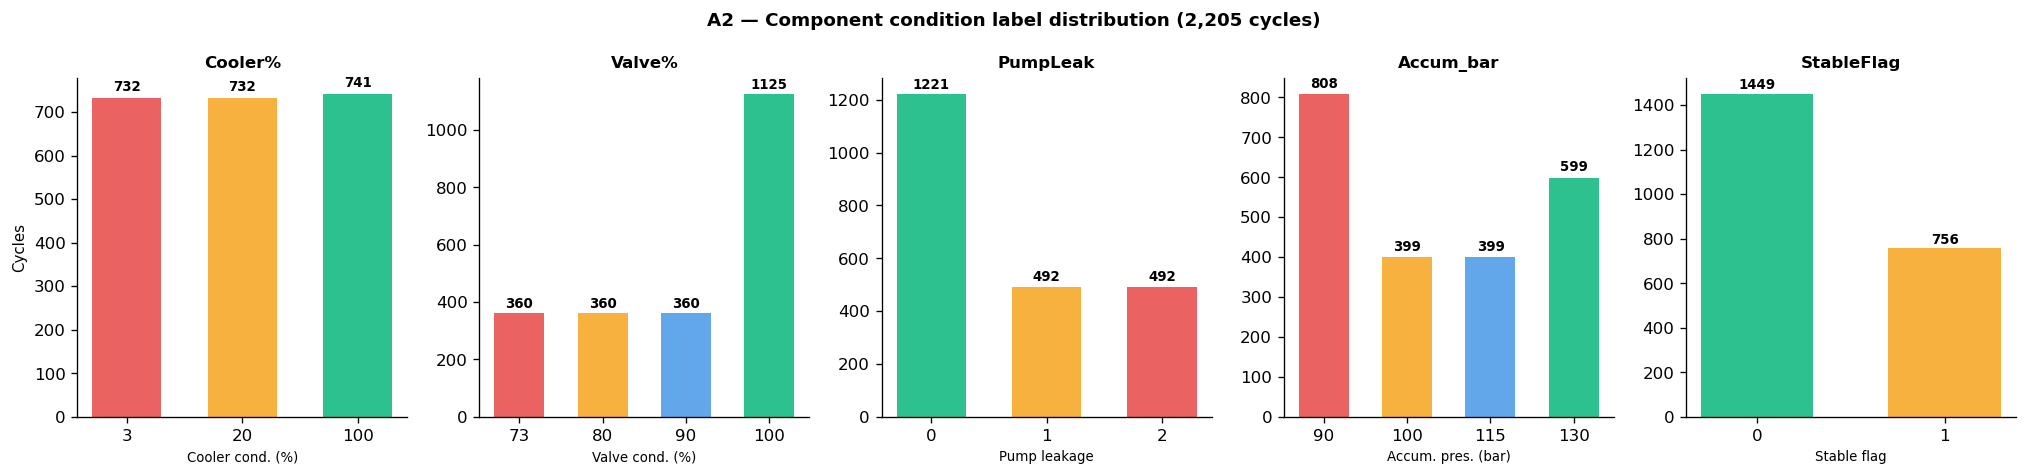

Saved: A2_condition_labels.png


In [6]:
LABELS = ["Cooler%","Valve%","PumpLeak","Accum_bar","StableFlag"]
PALS   = [COOLER_PAL, VALVE_PAL, PUMP_PAL, ACCUM_PAL, {0:"#10B981",1:"#F5A623"}]
DESCS  = ["Cooler cond. (%)","Valve cond. (%)","Pump leakage","Accum. pres. (bar)","Stable flag"]

print("Condition label distribution across 2,205 cycles:")
for i, lbl in enumerate(LABELS):
    vals, counts = np.unique(profile[:,i], return_counts=True)
    print(f"  {lbl:<12s}: " + "  |  ".join([f"{int(v)} -> {c} cycles" for v,c in zip(vals,counts)]))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
fig.suptitle("A2 — Component condition label distribution (2,205 cycles)",
             fontsize=11, fontweight="bold")

for ax, i, lbl, pal, desc in zip(axes, range(5), LABELS, PALS, DESCS):
    vals, counts = np.unique(profile[:,i], return_counts=True)
    bar_colors = [pal.get(int(v), "#94A3B8") for v in vals]
    bars = ax.bar([str(int(v)) for v in vals], counts, color=bar_colors, alpha=0.88, width=0.6)
    ax.set_title(lbl, fontsize=10, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8); ax.set_ylabel("Cycles" if i == 0 else "")
    for bar, cnt in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(cnt), ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig("A2_condition_labels.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_condition_labels.png")

## 6. Condition co-occurrence — which components degrade together?

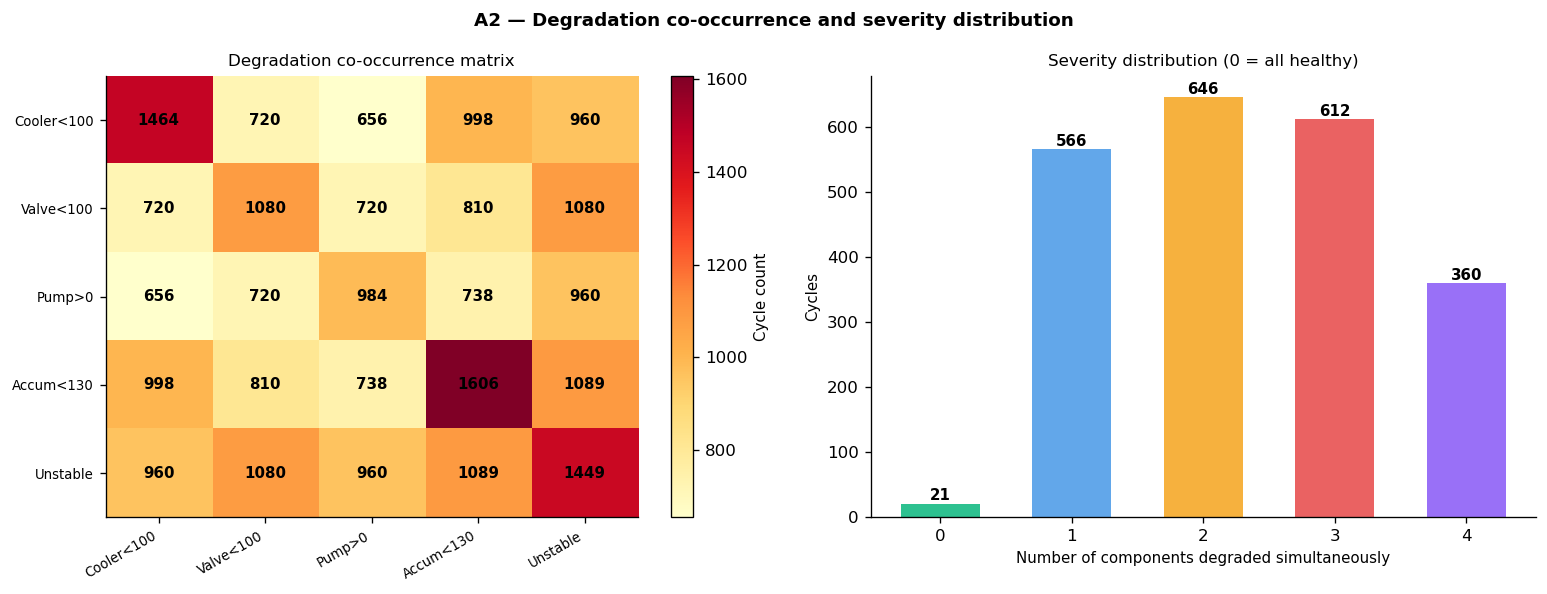

Saved: A2_cooccurrence.png

Severity breakdown:
  0 components degraded: 21 cycles (1.0%)
  1 components degraded: 566 cycles (25.7%)
  2 components degraded: 646 cycles (29.3%)
  3 components degraded: 612 cycles (27.8%)
  4 components degraded: 360 cycles (16.3%)


In [7]:
# Build a co-occurrence matrix: for each pair of components in degraded state,
# how many cycles have BOTH degraded simultaneously?
comp_degraded = {
    "Cooler<100":  cooler < 100,
    "Valve<100":   valve  < 100,
    "Pump>0":      pump   > 0,
    "Accum<130":   accum  < 130,
    "Unstable":    ~stable,
}
keys = list(comp_degraded.keys())
n    = len(keys)
cooc = np.zeros((n, n), dtype=int)
for i, (ki, vi) in enumerate(comp_degraded.items()):
    for j, (kj, vj) in enumerate(comp_degraded.items()):
        cooc[i, j] = (vi & vj).sum()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("A2 — Degradation co-occurrence and severity distribution",
             fontweight="bold", fontsize=11)

# Heatmap
im = ax0.imshow(cooc, cmap="YlOrRd", aspect="auto")
ax0.set_xticks(range(n)); ax0.set_xticklabels(keys, rotation=30, ha="right", fontsize=8)
ax0.set_yticks(range(n)); ax0.set_yticklabels(keys, fontsize=8)
for i in range(n):
    for j in range(n):
        ax0.text(j, i, str(cooc[i,j]), ha="center", va="center", fontsize=9, fontweight="bold")
plt.colorbar(im, ax=ax0, label="Cycle count")
ax0.set_title("Degradation co-occurrence matrix", fontsize=10)

# Severity histogram: number of degraded components per cycle
severity = (
    (cooler < 100).astype(int) +
    (valve  < 100).astype(int) +
    (pump   > 0  ).astype(int) +
    (accum  < 130).astype(int)
)
sev_vals, sev_counts = np.unique(severity, return_counts=True)
ax1.bar([str(v) for v in sev_vals], sev_counts,
        color=["#10B981","#4C9BE8","#F5A623","#E84C4C","#8B5CF6"][:len(sev_vals)],
        alpha=0.88, width=0.6)
ax1.set_xlabel("Number of components degraded simultaneously"); ax1.set_ylabel("Cycles")
ax1.set_title("Severity distribution (0 = all healthy)", fontsize=10)
for v, c in zip(sev_vals, sev_counts):
    ax1.text(v, c + 5, str(c), ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("A2_cooccurrence.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_cooccurrence.png")
print(f"\nSeverity breakdown:")
for v, c in zip(sev_vals, sev_counts):
    print(f"  {v} components degraded: {c} cycles ({c/2205*100:.1f}%)")

## 7. Degradation signatures — sensor response to component condition

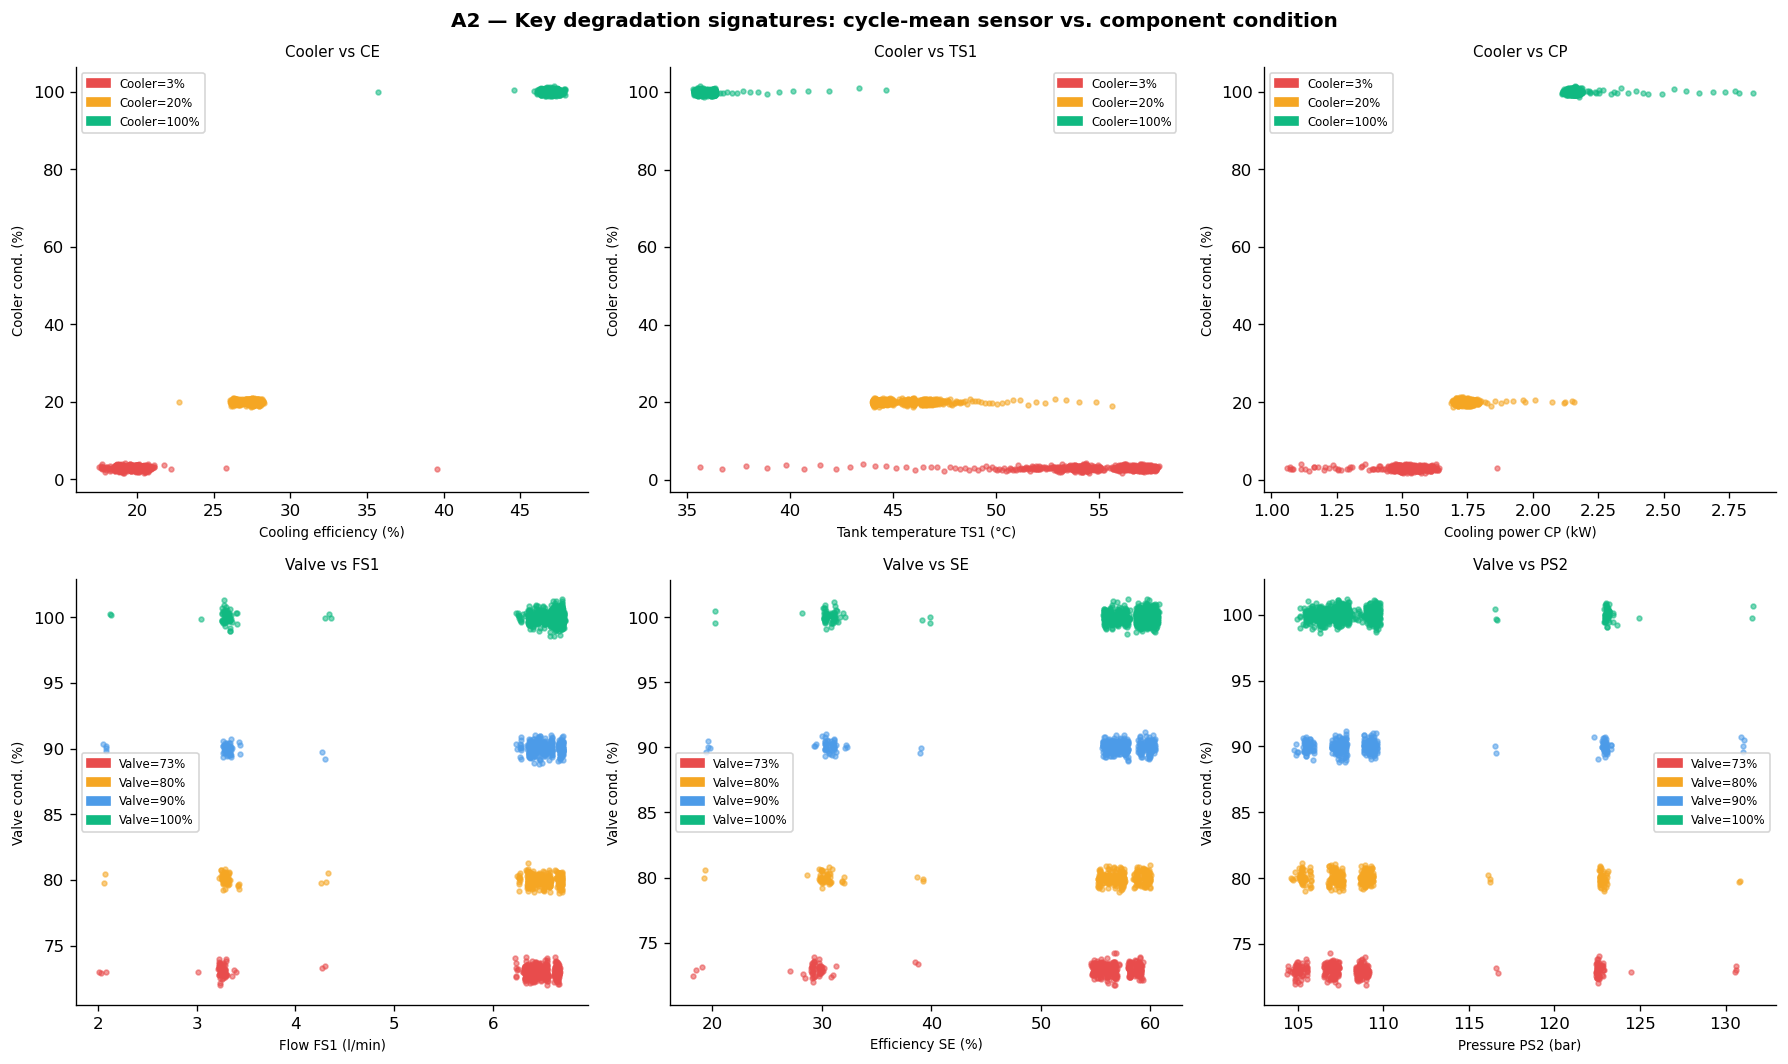

Saved: A2_degradation_signatures.png


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("A2 — Key degradation signatures: cycle-mean sensor vs. component condition",
             fontsize=12, fontweight="bold")

# ─── Row 0: Cooler condition ───────────────────────────────────────────────
pairs_cooler = [
    ("CE",  "Cooling efficiency (%)", COOLER_PAL, cooler, "Cooler cond. (%)"),
    ("TS1", "Tank temperature TS1 (°C)", COOLER_PAL, cooler, "Cooler cond. (%)"),
    ("CP",  "Cooling power CP (kW)",  COOLER_PAL, cooler, "Cooler cond. (%)"),
]
for ax, (sig, xlabel, pal, cond, ylabel) in zip(axes[0], pairs_cooler):
    for cval, ccolor in pal.items():
        mask = cond == cval
        ax.scatter(means[sig][mask],
                   np.random.normal(cval, 0.4, mask.sum()),
                   color=ccolor, s=8, alpha=0.55, label=f"{cval}")
    ax.set_xlabel(xlabel, fontsize=8); ax.set_ylabel(ylabel, fontsize=8)
    ax.set_title(f"Cooler vs {sig}", fontsize=9)
    patches = [mpatches.Patch(color=c, label=f"Cooler={v}%") for v, c in pal.items()]
    ax.legend(handles=patches, fontsize=7, markerscale=2)

# ─── Row 1: Valve condition ────────────────────────────────────────────────
pairs_valve = [
    ("FS1", "Flow FS1 (l/min)",    VALVE_PAL, valve, "Valve cond. (%)"),
    ("SE",  "Efficiency SE (%)",   VALVE_PAL, valve, "Valve cond. (%)"),
    ("PS2", "Pressure PS2 (bar)",  VALVE_PAL, valve, "Valve cond. (%)"),
]
for ax, (sig, xlabel, pal, cond, ylabel) in zip(axes[1], pairs_valve):
    for cval, ccolor in pal.items():
        mask = cond == cval
        ax.scatter(means[sig][mask],
                   np.random.normal(cval, 0.4, mask.sum()),
                   color=ccolor, s=8, alpha=0.55, label=f"{cval}")
    ax.set_xlabel(xlabel, fontsize=8); ax.set_ylabel(ylabel, fontsize=8)
    ax.set_title(f"Valve vs {sig}", fontsize=9)
    patches = [mpatches.Patch(color=c, label=f"Valve={v}%") for v, c in pal.items()]
    ax.legend(handles=patches, fontsize=7, markerscale=2)

plt.tight_layout()
plt.savefig("A2_degradation_signatures.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_degradation_signatures.png")

## 8. Pump and accumulator condition analysis

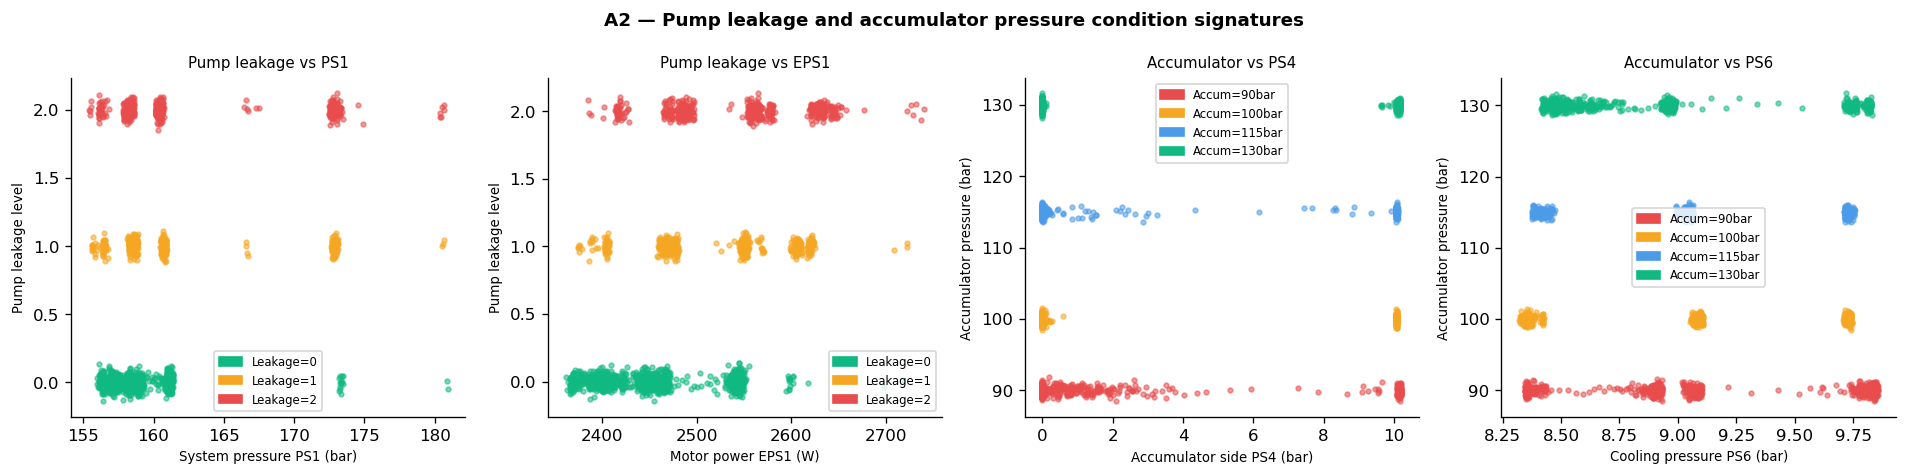

Saved: A2_pump_accumulator.png


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle("A2 — Pump leakage and accumulator pressure condition signatures",
             fontweight="bold", fontsize=11)

# Pump leakage vs PS1 and EPS1
for ax, (sig, xlabel) in zip(axes[:2], [("PS1","System pressure PS1 (bar)"),
                                          ("EPS1","Motor power EPS1 (W)")]):
    for pval, pcolor in PUMP_PAL.items():
        mask = pump == pval
        ax.scatter(means[sig][mask],
                   np.random.normal(pval, 0.04, mask.sum()),
                   color=pcolor, s=8, alpha=0.55, label=f"Leak={pval}")
    ax.set_xlabel(xlabel, fontsize=8); ax.set_ylabel("Pump leakage level", fontsize=8)
    ax.set_title(f"Pump leakage vs {sig}", fontsize=9)
    patches = [mpatches.Patch(color=c, label=f"Leakage={v}") for v, c in PUMP_PAL.items()]
    ax.legend(handles=patches, fontsize=7, markerscale=2)

# Accumulator vs PS4 and PS5
for ax, (sig, xlabel) in zip(axes[2:], [("PS4","Accumulator side PS4 (bar)"),
                                          ("PS6","Cooling pressure PS6 (bar)")]):
    for aval, acolor in ACCUM_PAL.items():
        mask = accum == aval
        ax.scatter(means[sig][mask],
                   np.random.normal(aval, 0.5, mask.sum()),
                   color=acolor, s=8, alpha=0.55, label=f"{aval} bar")
    ax.set_xlabel(xlabel, fontsize=8); ax.set_ylabel("Accumulator pressure (bar)", fontsize=8)
    ax.set_title(f"Accumulator vs {sig}", fontsize=9)
    patches = [mpatches.Patch(color=c, label=f"Accum={v}bar") for v, c in ACCUM_PAL.items()]
    ax.legend(handles=patches, fontsize=7, markerscale=2)

plt.tight_layout()
plt.savefig("A2_pump_accumulator.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_pump_accumulator.png")

## 9. Downsampling decision — 100 Hz → 1 Hz (with figure)

Raw data points / dataset    : 96,314,400
At 1 Hz (mean-per-second)    : 2,249,100
Reduction factor             : 43x

100 Hz MQTT bandwidth : 336,000 B/cycle  = 5600 B/s
1 Hz  MQTT bandwidth  : 136  B/cycle-s = 2.3 B/s
Bandwidth reduction   : 2471x


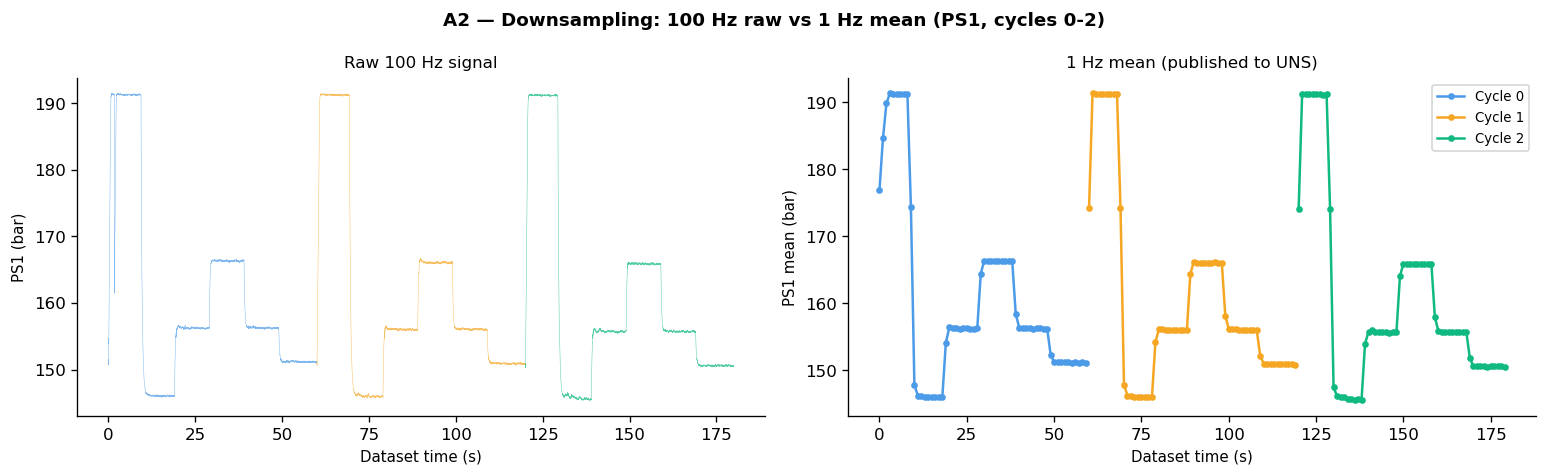

Saved: A2_downsampling.png

Preprocessed a2_1hz.npz: 4556 KB  (vs ~450 MB raw files)
  Keys: ['PS1', 'PS2', 'PS3', 'PS4', 'PS5', 'PS6', 'EPS1', 'FS1', 'FS2', 'TS1', 'TS2', 'TS3', 'TS4', 'VS1', 'CE', 'CP', 'SE', 'profile']
  ✓ a2_1hz.npz validated


In [10]:
n_cycles  = 2205
sps_raw   = {s: n_cycles * hz * 60 for s,(unit,hz) in SENSORS.items()}
total_raw = sum(sps_raw.values())
total_1hz = n_cycles * 60 * len(SENSORS)

print(f"Raw data points / dataset    : {total_raw:,}")
print(f"At 1 Hz (mean-per-second)    : {total_1hz:,}")
print(f"Reduction factor             : {total_raw/total_1hz:.0f}x")

bps_100hz = 7 * 6000 * 8
bps_1hz   = 17 * 8
print(f"\n100 Hz MQTT bandwidth : {bps_100hz:,} B/cycle  = {bps_100hz/60:.0f} B/s")
print(f"1 Hz  MQTT bandwidth  : {bps_1hz}  B/cycle-s = {bps_1hz/60:.1f} B/s")
print(f"Bandwidth reduction   : {bps_100hz/bps_1hz:.0f}x")

# Compare 100 Hz raw vs 1 Hz mean for PS1 — first 3 cycles
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("A2 — Downsampling: 100 Hz raw vs 1 Hz mean (PS1, cycles 0-2)",
             fontweight="bold", fontsize=11)

for cy, color in zip([0, 1, 2], ["#4C9BE8","#F5A623","#10B981"]):
    t100 = np.linspace(cy*60, (cy+1)*60, 6000)
    axes[0].plot(t100, data["PS1"][cy], lw=0.3, color=color, alpha=0.7)

    t1   = np.arange(cy*60, (cy+1)*60)
    mean_1hz = data["PS1"][cy].reshape(60, 100).mean(axis=1)
    axes[1].plot(t1, mean_1hz, lw=1.5, color=color, marker="o", ms=3, label=f"Cycle {cy}")

axes[0].set_xlabel("Dataset time (s)"); axes[0].set_ylabel("PS1 (bar)")
axes[0].set_title("Raw 100 Hz signal")
axes[1].set_xlabel("Dataset time (s)"); axes[1].set_ylabel("PS1 mean (bar)")
axes[1].set_title("1 Hz mean (published to UNS)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("A2_downsampling.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: A2_downsampling.png")

if PREP.exists():
    npz = np.load(PREP)
    print(f"\nPreprocessed {PREP.name}: {PREP.stat().st_size/1024:.0f} KB  (vs ~450 MB raw files)")
    print(f"  Keys: {list(npz.files)}")
    print("  ✓ a2_1hz.npz validated")
else:
    print("  [INFO] a2_1hz.npz not found — run: python -m sim.tools.prepare_a2")

## 10. Simulator validation summary

In [11]:
print("Simulator validation (sim/assets/a2_hydraulic.py + sim/tools/prepare_a2)")
print("="*62)
print(f"  Cycles           : 2,205  (verified from all sensor file shapes)")
print(f"  Published rate   : 1 Hz (60 samples/cycle after mean-per-second)")
print(f"  Condition labels : published at cycle start (per-cycle ground truth)")
print()
print("  Tag dtype mapping:")
tag_types = [
    ("Hydraulic/PS1_bar",            "Double",  "float64 pressure — 100 Hz source, 1 Hz published"),
    ("Motor/Vibration_mms",          "Double",  "float64 vibration  PLC alarm > 0.8 mm/s"),
    ("KPIs/CoolingEfficiency_pct",   "Double",  "float64 virtual KPI  PLC alarm < 30%"),
    ("Condition/CoolerCondition_pct","Int64",   "ordinal label {3, 20, 100}  ground-truth only"),
    ("Condition/PumpLeakage",        "Int64",   "ordinal label {0, 1, 2}  ground-truth only"),
    ("Condition/StableFlag",         "Boolean", "stable cycle flag  filter unstable cycles in ML"),
]
for tag, otype, reason in tag_types:
    print(f"    {tag:<42s}: {otype:<8s}  ({reason})")
print()
print("All sensor ranges, label distributions, and replay decisions validated.")
print("A2_EDA.ipynb satisfies Phase 2 deliverable requirements.")
print()
print("Figures produced:")
for fig in ["A2_sensor_distributions.png","A2_cycle_multirate.png",
            "A2_condition_labels.png","A2_cooccurrence.png",
            "A2_degradation_signatures.png","A2_pump_accumulator.png",
            "A2_downsampling.png"]:
    print(f"  {fig}")

Simulator validation (sim/assets/a2_hydraulic.py + sim/tools/prepare_a2)
  Cycles           : 2,205  (verified from all sensor file shapes)
  Published rate   : 1 Hz (60 samples/cycle after mean-per-second)
  Condition labels : published at cycle start (per-cycle ground truth)

  Tag dtype mapping:
    Hydraulic/PS1_bar                         : Double    (float64 pressure — 100 Hz source, 1 Hz published)
    Motor/Vibration_mms                       : Double    (float64 vibration  PLC alarm > 0.8 mm/s)
    KPIs/CoolingEfficiency_pct                : Double    (float64 virtual KPI  PLC alarm < 30%)
    Condition/CoolerCondition_pct             : Int64     (ordinal label {3, 20, 100}  ground-truth only)
    Condition/PumpLeakage                     : Int64     (ordinal label {0, 1, 2}  ground-truth only)
    Condition/StableFlag                      : Boolean   (stable cycle flag  filter unstable cycles in ML)

All sensor ranges, label distributions, and replay decisions validated.
A2_E